<h2>
  Vignette 01: platpy basics (Spatial Registration)<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"Home is where I want to be, but I guess I'm already there" — Talking Heads</i>
  </span>
</h2>

Platpy is designed around a simple but useful concept: "Micron Space." Once your data is loaded, everything—from an 8µm Visium spot to a 0.5µm DAPI pixel—is anchored to a shared, absolute physical coordinate system via `SpatialMetadata`. You no longer have to worry about pixels, downsampling, or tracking alignment matrices when interacting with your data.  All the different types of data are at home in the same space.


### Step 1: Loading sample Visium dataset

Here we use the 'load_visium_directory' and 'add_visium_fullres_channel' functions to ingest the spot data from the sample set, and place it into the master object class that we will use to store our samples: the 'SampleSet'.  Each 'SampleSet' object can hold all the relevant data types used in a spatial experiment.  Each dataset is referred to as a Channel.  There are several types of channels:
+ OmicChannel: holds the spatial-transcript data; in this case spot data
+ ImageChannel: holds regular images, in this case IF images at multiple resolutions
+ ROIChannel: holds polygons that map out ROIs selected for analysis

Each channel contains the image in native format, plus metadata that is used to map to "home": Micron Space.

#### NOTE: This demo will automatically load pre-saved sample data from Zenodo to the save path specified below.  If you'd prefer to build your own dataset from raw 10x files, see Vignette_00 for details.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import os
import numpy as np; import pandas as pd; import matplotlib.pyplot as plt
from platpy.io_utils import load_sample, save_sample
from platpy.visium_loader import load_visium_directory, add_visium_fullres_channel
from platpy.channels import SampleSet, ImageChannel, OmicChannel, CellChannel, ROIChannel
from platpy.transform_utils import SpatialMetadata
from platpy.demo_utils import fetch_zenodo_bundle

# --- UPDATE THIS PATH if you'd like to store the data somewhere else ---
save_path = Path.home() / 'platpy_data' / 'VisiumSample'

# --- AUTOMATICALLY DOWNLOAD SAMPLE DATA FROM ZENODO ---
fetch_zenodo_bundle(save_path,
    'https://zenodo.org/records/20320692/files/VisiumSample.zip')

print("Loading from saved platpy bundle...")
sample = load_sample(save_path, verbose=True)

print(f"\nSample: {sample.name}")
print(f"  Omic channels : {list(sample.omics.keys())}")
print(f"  Image channels: {list(sample.images.keys())}")

Loading from saved platpy bundle...
  - Images available: 'dapi' (16g), 'neun' (16g), 'detected' (24c), 'lowres' (24c), 'hires' (24c)


  - Image channels loaded: dapi, neun, detected, lowres, hires
  - Omic channels loaded: spots
  - Cell channels loaded: 
  - ROIs loaded: 

Sample: VisiumSample
  Omic channels : ['spots']
  Image channels: ['dapi', 'neun', 'detected', 'lowres', 'hires']


#### The problem platpy solves: native spatial data is challenging to work with

10x Visium datasets exemplify the issues in processing spatial genomic data.  Visium data is processed by SpaceRanger, and the raw output contains both images and transcript data assigned to spatial locations ('spots').  The images are standard images, and the spot data is processed as an anndata dataframe with (x,y) coordinates in microns.

The raw data for each is very different in nature.

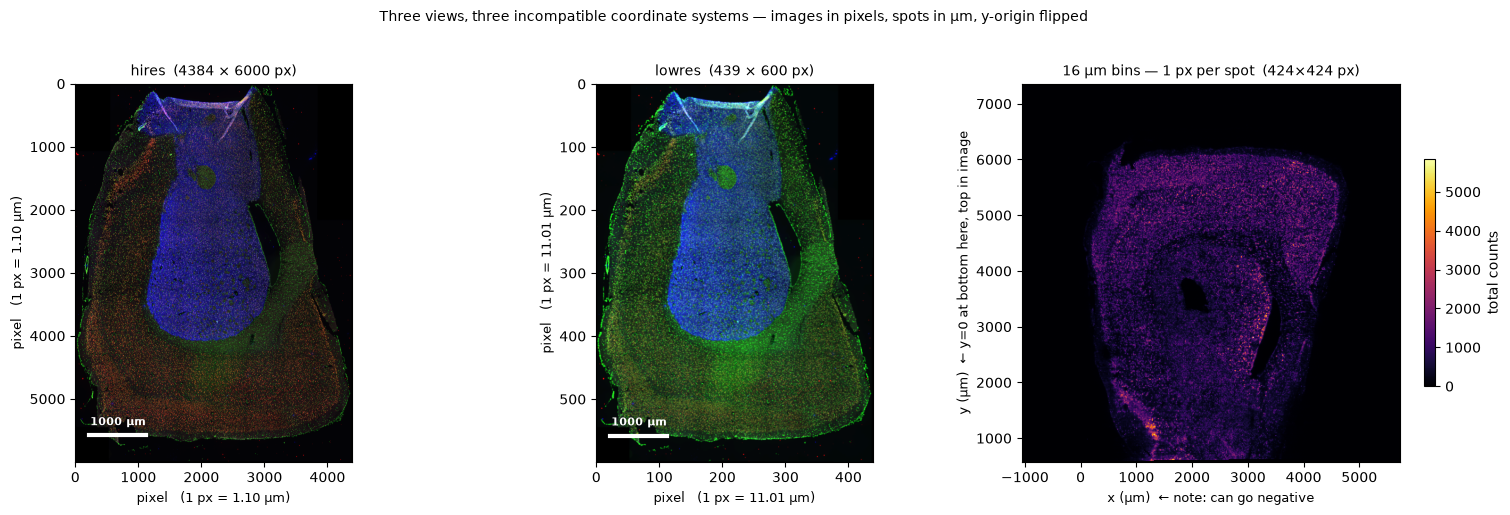

hires  scale: 0.29576  →  1.101 µm/px
lowres scale: 0.02958  →  11.011 µm/px
spots extent: x [-1056, 5712] µm   y [576, 7344] µm


In [2]:
sf       = sample.metadata.get('scalefactors', {})
mpp      = sf.get('microns_per_pixel', 1.0)
hires_sf = sf.get('tissue_hires_scalef', 1.0)
lowres_sf = sf.get('tissue_lowres_scalef', 1.0)

lowres_img = sample.images['lowres'].image
hires_img = sample.images['hires'].image
if hasattr(lowres_img, 'compute'):
    lowres_img = lowres_img.compute()

hires_um_per_px  = mpp / hires_sf
lowres_um_per_px = mpp / lowres_sf

# Build a 1-pixel-per-spot total-counts image from the 16 µm bin
spots_16  = sample.omics['spots'].get_optimal_level(16.0)[1]
coords    = spots_16.obsm['spatial']                           # µm (x, y)
counts    = spots_16.obs['total_counts'].values.astype(float)

bin_um  = 16.0
x_bin   = np.round(coords[:, 0] / bin_um).astype(int)
y_bin   = np.round(coords[:, 1] / bin_um).astype(int)
x0, x1  = x_bin.min(), x_bin.max()
y0, y1  = y_bin.min(), y_bin.max()
spot_img = np.zeros((y1 - y0 + 1, x1 - x0 + 1))
spot_img[y_bin - y0, x_bin - x0] = counts
# extent in µm so axes show real coordinates — negatives included
extent_um = [x0 * bin_um, (x1 + 1) * bin_um, y0 * bin_um, (y1 + 1) * bin_um]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(hires_img)
axes[0].set_title(f'hires  ({hires_img.shape[1]} × {hires_img.shape[0]} px)', fontsize=10)
axes[0].set_xlabel(f'pixel   (1 px = {hires_um_per_px:.2f} µm)', fontsize=9)
axes[0].set_ylabel(f'pixel   (1 px = {hires_um_per_px:.2f} µm)', fontsize=9)

axes[1].imshow(lowres_img)
axes[1].set_title(f'lowres  ({lowres_img.shape[1]} × {lowres_img.shape[0]} px)', fontsize=10)
axes[1].set_xlabel(f'pixel   (1 px = {lowres_um_per_px:.2f} µm)', fontsize=9)
axes[1].set_ylabel(f'pixel   (1 px = {lowres_um_per_px:.2f} µm)', fontsize=9)

im = axes[2].imshow(spot_img, origin='lower', cmap='inferno',
                    extent=extent_um, aspect='equal')
plt.colorbar(im, ax=axes[2], label='total counts', shrink=0.6)
axes[2].set_title(f'16 µm bins — 1 px per spot  ({spot_img.shape[1]}×{spot_img.shape[0]} px)', fontsize=10)
axes[2].set_xlabel('x (µm)  ← note: can go negative', fontsize=9)
axes[2].set_ylabel('y (µm)  ← y=0 at bottom here, top in image', fontsize=9)

# 1000 µm scale bar on the image panels
for ax, upm, img in [(axes[0], hires_um_per_px, hires_img),
                     (axes[1], lowres_um_per_px, lowres_img)]:
    bar_px = 1000 / upm
    by = img.shape[0] * 0.93
    bx = img.shape[1] * 0.05
    ax.plot([bx, bx + bar_px], [by, by], 'w-', linewidth=3)
    ax.text(bx + bar_px/2, by - img.shape[0]*0.02, '1000 µm',
            color='white', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle('Three views, three incompatible coordinate systems — '
             'images in pixels, spots in µm, y-origin flipped',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

print(f"hires  scale: {hires_sf:.5f}  →  {hires_um_per_px:.3f} µm/px")
print(f"lowres scale: {lowres_sf:.5f}  →  {lowres_um_per_px:.3f} µm/px")
print(f"spots extent: x [{x0*bin_um:.0f}, {x1*bin_um:.0f}] µm   "
      f"y [{y0*bin_um:.0f}, {y1*bin_um:.0f}] µm")

#### Working with data across layers is challenging

SpaceRanger does provide metadata (scale factors) that allow aligning images and spots together, and this is straightforward when you want to align full images.  But what happens when you want to crop an image?  Rotate an image?  Or importantly for analysis, what about making an ROI to select just the data from a specific structure? 

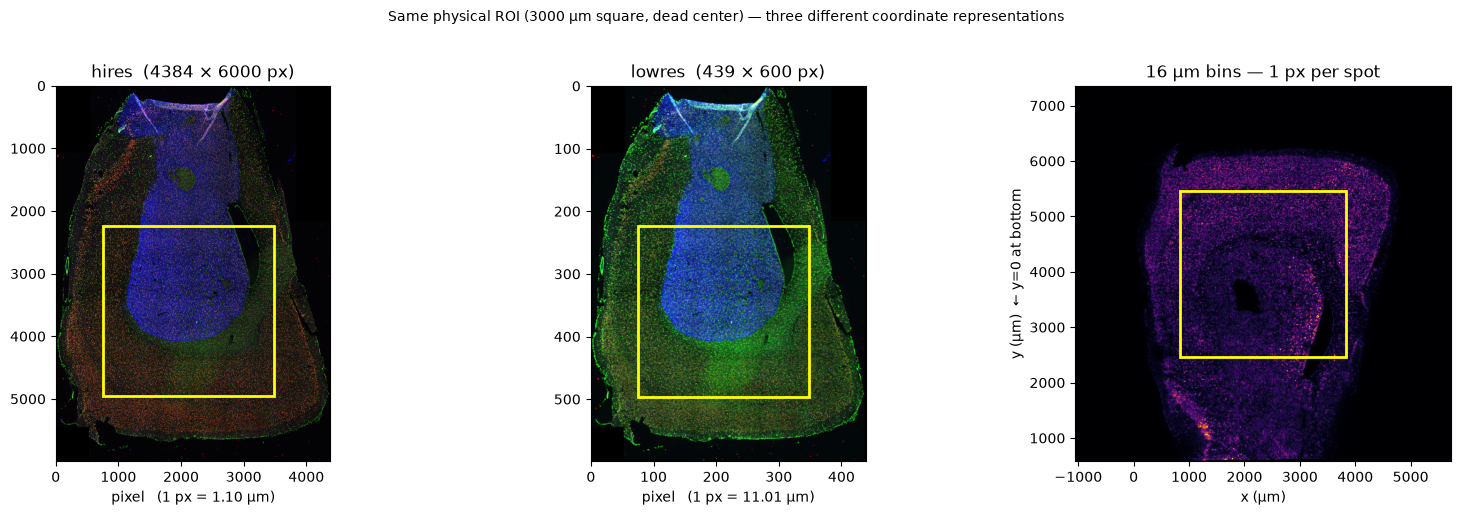

Same physical region, three coordinate systems:
  hires  pixels:  x [752, 3477]  y [2234, 4959]
  lowres pixels:  x [75, 348]  y [223, 496]
  spots  µm:      x [828, 3828]  y [2460, 5460]

  ...and that's for a square ROI before rotation, flipping, or multi-sample alignment.


In [3]:
import matplotlib.patches as mpatches

# Define the ROI as a 3000 µm square centered on the tissue
half_um = 1500.0
cx_um   = (x0 + x1) / 2 * bin_um
cy_um   = (y0 + y1) / 2 * bin_um

# Compute ROI boundaries in each coordinate system
roi_hires_x  = (cx_um - half_um) * hires_sf / mpp
roi_hires_y  = (cy_um - half_um) * hires_sf / mpp
roi_hires_w  = 2 * half_um * hires_sf / mpp

roi_lowres_x = (cx_um - half_um) * lowres_sf / mpp
roi_lowres_y = (cy_um - half_um) * lowres_sf / mpp
roi_lowres_w = 2 * half_um * lowres_sf / mpp

# Spot render is already in µm, origin='lower' so y is not flipped on the axis
roi_spot_x   = cx_um - half_um
roi_spot_y   = cy_um - half_um   # y=0 at bottom in spot render
roi_spot_w   = 2 * half_um

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(hires_img)
axes[0].add_patch(mpatches.Rectangle(
    (roi_hires_x, roi_hires_y), roi_hires_w, roi_hires_w,
    linewidth=2, edgecolor='yellow', facecolor='none'))
axes[0].set_title(f'hires  ({hires_img.shape[1]} × {hires_img.shape[0]} px)')
axes[0].set_xlabel(f'pixel   (1 px = {hires_um_per_px:.2f} µm)')

axes[1].imshow(lowres_img)
axes[1].add_patch(mpatches.Rectangle(
    (roi_lowres_x, roi_lowres_y), roi_lowres_w, roi_lowres_w,
    linewidth=2, edgecolor='yellow', facecolor='none'))
axes[1].set_title(f'lowres  ({lowres_img.shape[1]} × {lowres_img.shape[0]} px)')
axes[1].set_xlabel(f'pixel   (1 px = {lowres_um_per_px:.2f} µm)')

axes[2].imshow(spot_img, origin='lower', cmap='inferno', extent=extent_um, aspect='equal')
axes[2].add_patch(mpatches.Rectangle(
    (roi_spot_x, roi_spot_y), roi_spot_w, roi_spot_w,
    linewidth=2, edgecolor='yellow', facecolor='none'))
axes[2].set_title(f'16 µm bins — 1 px per spot')
axes[2].set_xlabel('x (µm)')
axes[2].set_ylabel('y (µm)  ← y=0 at bottom')

plt.suptitle('Same physical ROI (3000 µm square, dead center) — three different coordinate representations',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

print("Same physical region, three coordinate systems:")
print(f"  hires  pixels:  x [{roi_hires_x:.0f}, {roi_hires_x+roi_hires_w:.0f}]  "
      f"y [{roi_hires_y:.0f}, {roi_hires_y+roi_hires_w:.0f}]")
print(f"  lowres pixels:  x [{roi_lowres_x:.0f}, {roi_lowres_x+roi_lowres_w:.0f}]  "
      f"y [{roi_lowres_y:.0f}, {roi_lowres_y+roi_lowres_w:.0f}]")
print(f"  spots  µm:      x [{roi_spot_x:.0f}, {roi_spot_x+roi_spot_w:.0f}]  "
      f"y [{roi_spot_y:.0f}, {roi_spot_y+roi_spot_w:.0f}]")
print(f"\n  ...and that's for a square ROI before rotation, flipping, or multi-sample alignment.")

#### Organizing all the data layers

To tackle the challenge of working with the **spatial** part of spatial data, we developed platpy: **P**ipeline for **L**ayered **A**nalysis of **T**ranscriptomics.

Platpy organizes your images and 'omic data into two channels: `sample.images` for morphology images and `sample.omics` for transcript data. Each channel carries its own `SpatialMetadata`, so everything is already registered to a shared micron coordinate system — no alignment step needed.

In the following cell you'll see that we can use platpy's render feature `render_omic_to_image()` to create a matched pair with the fluorescent image and the transcript expression (in this case, total counts/bin).  Rendering the 'omic image is fast, takes one line of code, and the render feature has all the "knobs and settings" needed to adjust the view how you want it.

Image channels : ['dapi', 'neun', 'detected', 'lowres', 'hires']
Omic channels  : ['spots']


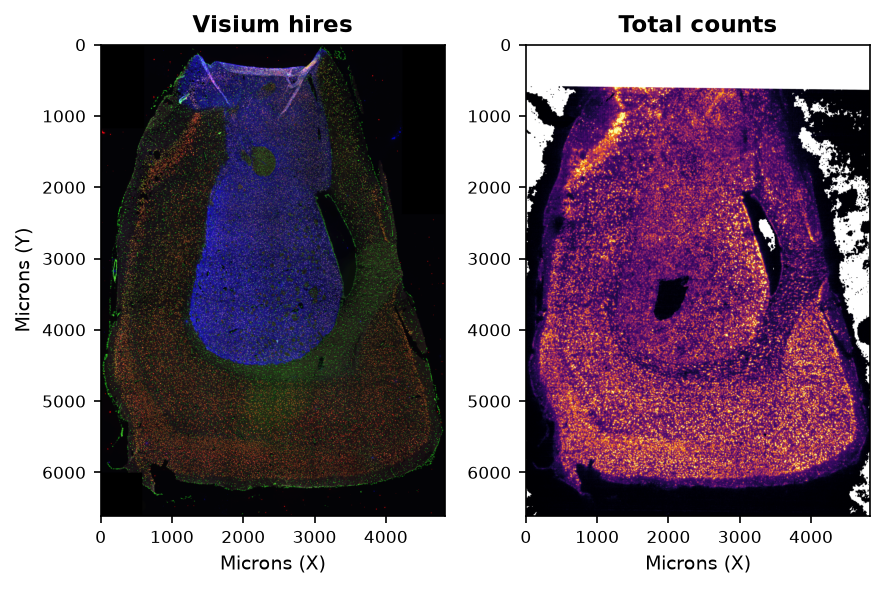

In [4]:
from platpy.plot_utils import plot_image_grid
from platpy.render_utils import render_omic_to_image

print('Image channels :', list(sample.images.keys()))
print('Omic channels  :', list(sample.omics.keys()))

total_render = render_omic_to_image(
    omic=sample.omics['spots'],         # we're looking at the 'spot' level dataset
    base_image=sample.images['hires'],  # we want our render to perfectly align with the 'hires' image channel
    gene_name='total_counts',           # let's look at the total counts per spot (all transcripts)
    cmap_name='inferno',                # we can choose from a variety of colormaps - e.g., 'viridis', 'plasma', 'inferno', 'magma', or any matplotlib colormap
    percentile_clip=(5, 99),            # this controls the brightness by clipping the outliers to plot where the interesting signal is
    gamma=0.8                           # gamma is a standard image adjustment for contrast setting
)

plot_image_grid(                                # This is our simple plot utility that sits on top of matplotlib.
    [sample.images['hires'], total_render],     # This is all it takes to plot the images -- just list them and go!
    titles=['Visium hires', 'Total counts'],
    width=6
);

# Note: for those that prefer matplotlib directly, the above is equivalent to:
# fig, axes = plt.subplots(1, 2, figsize=(8, 4))
# axes[0].imshow(sample.images['hires'].image)
# axes[0].set_title('Visium hires')
# axes[1].imshow(total_render)
# axes[1].set_title('Total counts')
# plt.show()

#### Step 3: All coordinates are in microns

Every channel in platpy — images, spots, cell boundaries — is anchored to the same absolute physical coordinate system measured in microns. That means you can crop any channel using real-world coordinates and everything lines up, regardless of the channel's native resolution.

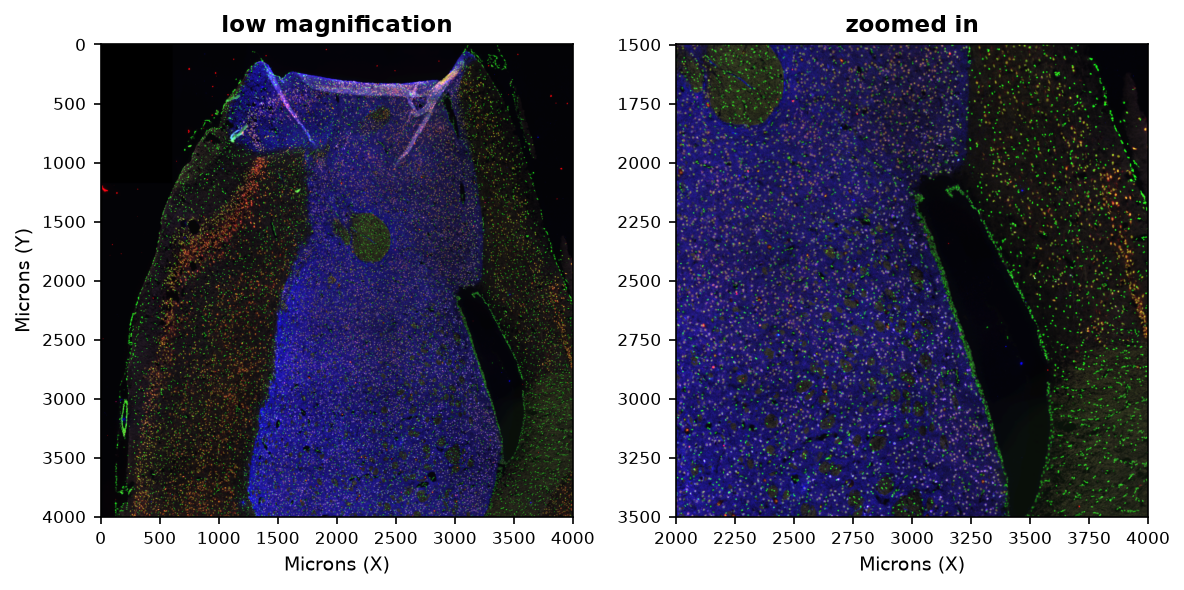

In [5]:
from platpy.plot_utils import plot_image_grid

# Crop any channel to the same micron ROI — alignment is automatic
roi1 = [0,0,4000, 4000]
roi2 = [2000, 1500, 4000, 3500]   # x_min, y_min, x_max, y_max in microns

plot_image_grid(
    [sample.images['hires'].crop_to_micron_roi(roi1),       # roi1 is an overview of the whole sample
     sample.images['hires'].crop_to_micron_roi(roi2)],      # roi2 is a zoomed in region in the middle
    titles=['low magnification', 'zoomed in'],
    width=8, uniform_size=True
);                                                          

# alignment is automatic becasue the channels all have spatial metadata that maps them to the micron space of the actual sample.


#### Next: Using the ViewPort to see your images and data quickly

In this example, you may have noticed a few key things:

 - **The datasets were loaded quickly and efficiently.**  Platpy uses a set of efficient tools available in Python -- Dask and Zarr -- to store large datasets.  This includes features like "lazy loading", where large datasets are broken into segments, and only the parts  you need are loaded.  This keeps the program running faster, and the memory footprint smaller.
 - **Platpy generates very high quality images.**  The rendering of both images and data are designed to be optimized for both speed and quality.  Both images and spot data are stored at several resolutions, and the rendering algorithms choose the appropriate one to use.  You don't have to wait to process a massive image or dataset to render a thumbnail; and it doesn't render things that are out of view.

In the next section, we will introduce the ViewPort, which is a straightforward way to view your data in all its glory.  
The ViewPort allows for creating custom layered images.  You can scale, flip, rotate to get the perfect view.
You have all the "knobs" needed to adjust the image to look just how you want it.  And even more "knobs" to render perfect views of expression data, and finally to create ROIs that you want to examine. 